# S0 — 02.08: Decision Tree Regression

**Question:** How can a regression tree predict different constant values in different regions, and why does a greedy split not guarantee the globally best tree?

This lesson uses eight synthetic, dimensionless observations for deterministic training arithmetic. It makes no claim about predictive performance, generalisation, causality, or superiority. Classification criteria, pruning, ensembles, cross-validation, feature importance, inference, and deployment are outside scope.

## S1 — Regions, nodes, and shapes

A **region** is the samples reaching a node. The root is depth 0; an internal node splits into two children; a leaf stops and predicts one constant. A threshold is written `x_j <= t`, and depth is not the same as leaf count. Here `X.shape == (8, 1)` means eight samples and one feature, while `y.shape == (8,)` has one target per sample.

## S2 — Frozen data and regions

The feature values are ordered from 1 through 8 and the targets form a small rise-and-fall pattern. The parent region is `{1..8}`. A split partitions only the samples that reach the current region; later child regions need not contain every feature value. The secondary two-feature example is reserved for later code and cross-checks.

In [1]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

np.set_printoptions(precision=5, suppress=True)
RTOL = 0.0
ATOL = 1e-12
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0], dtype=np.float64)
y = np.array([2.2, 1.8, 5.0, 4.8, 8.2, 8.0, 5.0, 5.0], dtype=np.float64)
X = x.reshape(8, 1)
print(f"X.shape={X.shape}, y.shape={y.shape}, dtype={X.dtype}")

X.shape=(8, 1), y.shape=(8,), dtype=float64


## S3 — A leaf predicts its region mean

For a region `R`, `y_hat_R = mean(y_R)` and `RSS_R = sum((y_i - y_hat_R)**2)`. The identity `sum((y_i-c)**2) = RSS_R + N_R*(c-y_hat_R)**2` proves that the mean is the squared-error minimizer. The parent mean is `5.0`, parent RSS is `37.36`, and parent MSE is `4.67`.

In [2]:
def region_stats(targets, indices):
    values = targets[indices]
    mean = np.float64(np.mean(values, dtype=np.float64))
    rss = np.float64(np.sum((values - mean) ** 2, dtype=np.float64))
    return mean, rss

parent_mean, parent_rss = region_stats(y, np.arange(8))
print("parent mean:", parent_mean, "parent RSS:", parent_rss, "parent MSE:", parent_rss / 8)
right_mean, right_rss = region_stats(y, np.arange(2, 8))
print("{3..8} mean:", right_mean, "RSS:", right_rss)

parent mean: 5.0 parent RSS: 37.36 parent MSE: 4.67
{3..8} mean: 6.0 RSS: 13.279999999999998


## S4 — Candidate midpoints and greedy gain

Within a region, use midpoints of consecutive sorted unique feature values. For a valid split, `RSS_split = RSS_left + RSS_right` and `Delta_RSS = RSS_parent - RSS_split`. Both children need at least two samples. The algorithm chooses the largest valid gain, then recurses. A zero gain does not split.

In [3]:
def find_best_split(X, y, indices, min_samples_leaf):
    parent_mean, parent_rss = region_stats(y, indices)
    del parent_mean
    best = None
    for feature_index in range(X.shape[1]):
        values = np.unique(X[indices, feature_index])
        for threshold in (values[:-1] + values[1:]) / 2.0:
            left_mask = X[indices, feature_index] <= threshold
            left = indices[left_mask]
            right = indices[~left_mask]
            if left.size < min_samples_leaf or right.size < min_samples_leaf:
                continue
            _, left_rss = region_stats(y, left)
            _, right_rss = region_stats(y, right)
            gain = np.float64(parent_rss - left_rss - right_rss)
            if best is None or gain > best["gain"]:
                best = {"feature": feature_index, "threshold": np.float64(threshold),
                        "gain": gain, "left": left.copy(), "right": right.copy()}
    return best

root_split = find_best_split(X, y, np.arange(8), 2)
print(root_split["feature"], root_split["threshold"], root_split["gain"])

0 2.5 24.000000000000004


## S5 — Complete root audit

The root candidates include invalid singleton splits so the validity rule is visible. The winning split is `x <= 2.5`: left mean `2.0`, left RSS `0.08`; right mean `6.0`, right RSS `13.28`; split RSS `13.36`; gain `24.0`. The runner-up is `x <= 4.5` with gain `19.22`, a margin of `4.78`.

In [4]:
def candidate_rows(X, y, indices, min_samples_leaf):
    _, parent_rss = region_stats(y, indices)
    rows = []
    for feature_index in range(X.shape[1]):
        values = np.unique(X[indices, feature_index])
        for threshold in (values[:-1] + values[1:]) / 2.0:
            mask = X[indices, feature_index] <= threshold
            left, right = indices[mask], indices[~mask]
            left_mean, left_rss = region_stats(y, left)
            right_mean, right_rss = region_stats(y, right)
            rows.append((float(threshold), int(left.size), int(right.size),
                         left.size >= min_samples_leaf and right.size >= min_samples_leaf,
                         float(left_mean), float(right_mean), float(left_rss),
                         float(right_rss), float(left_rss + right_rss),
                         float(parent_rss - left_rss - right_rss)))
    return rows

print("threshold  n_left n_right valid mean_left mean_right RSS_left RSS_right RSS_split gain")
for row in candidate_rows(X, y, np.arange(8), 2):
    print(row)

threshold  n_left n_right valid mean_left mean_right RSS_left RSS_right RSS_split gain
(1.5, 1, 7, False, 2.2, 5.3999999999999995, 0.0, 28.4, 28.4, 8.96)
(2.5, 2, 6, True, 2.0, 6.0, 0.08000000000000004, 13.279999999999998, 13.359999999999998, 24.000000000000004)
(3.5, 3, 5, True, 3.0, 6.2, 6.08, 12.079999999999998, 18.159999999999997, 19.200000000000003)
(4.5, 4, 4, True, 3.45, 6.55, 8.51, 9.629999999999999, 18.14, 19.220000000000002)
(5.5, 5, 3, True, 4.4, 6.0, 26.559999999999995, 6.0, 32.559999999999995, 4.800000000000004)
(6.5, 6, 2, True, 5.0, 5.0, 37.36, 0.0, 37.36, 0.0)
(7.5, 7, 1, False, 5.0, 5.0, 37.36, 0.0, 37.36, 0.0)


## S6 — Recursive tree and predictions

Stopping order is: depth limit, no valid candidate, then best gain `<= 0`. The left child `{1,2}` stops at depth 1 because its only candidate would create two singletons. The right child `{3..8}` chooses `x <= 4.5`, with gain `3.63` and margin `0.63`. At depth 2 the leaves stop.

In [5]:
from dataclasses import dataclass

@dataclass
class Node:
    prediction: np.float64
    depth: int
    feature: int | None = None
    threshold: np.float64 | None = None
    left: object = None
    right: object = None

    @property
    def is_leaf(self):
        return self.left is None and self.right is None

def build_tree(X, y, indices, depth=0, max_depth=2, min_samples_leaf=2):
    prediction, rss = region_stats(y, indices)
    if depth >= max_depth:
        return Node(prediction, depth)
    split = find_best_split(X, y, indices, min_samples_leaf)
    if split is None or split["gain"] <= 0.0:
        return Node(prediction, depth)
    return Node(prediction, depth, split["feature"], split["threshold"],
                build_tree(X, y, split["left"], depth + 1, max_depth, min_samples_leaf),
                build_tree(X, y, split["right"], depth + 1, max_depth, min_samples_leaf))

def predict(node, X_new):
    values = []
    for row in np.asarray(X_new, dtype=np.float64):
        current = node
        while not current.is_leaf:
            current = current.left if row[current.feature] <= current.threshold else current.right
        values.append(current.prediction)
    return np.asarray(values, dtype=np.float64)

tree = build_tree(X, y, np.arange(8))
y_hat = predict(tree, X)
residuals = y - y_hat
print("training predictions:", y_hat)
print("residuals:", residuals)
print("tree RSS:", np.sum(residuals ** 2), "MSE:", np.mean(residuals ** 2))
np.testing.assert_allclose(y_hat, [2.0, 2.0, 4.9, 4.9, 6.55, 6.55, 6.55, 6.55], rtol=RTOL, atol=ATOL)

training predictions: [2.   2.   4.9  4.9  6.55 6.55 6.55 6.55]
residuals: [ 0.2  -0.2   0.1  -0.1   1.65  1.45 -1.55 -1.55]
tree RSS: 9.729999999999999 MSE: 1.2162499999999998


## S7 — Boundary traversal and the global comparison

Prediction follows `x <= threshold` to the left. Therefore `2.5` goes to the `2.0` leaf and `4.5` goes to the `4.9` leaf. The greedy tree has RSS `9.73`. Exhaustively checking contiguous partitions with at most four leaves finds RSS `0.12` at cuts `2.5`, `4.5`, and `6.5` in a different root arrangement. This is a bounded demonstration of local greedy choice, not a general performance claim.

In [6]:
X_new = np.array([[2.5], [3.7], [4.5], [7.2]], dtype=np.float64)
print("new predictions:", predict(tree, X_new))

def partition_rss(cuts):
    boundaries = (0, *cuts, len(y))
    return sum(region_stats(y, np.arange(boundaries[i], boundaries[i + 1]))[1]
               for i in range(len(boundaries) - 1))

partitions = []
from itertools import combinations
for count in range(1, 4):
    for cuts in combinations(range(2, 7), count):
        boundaries = (0, *cuts, 8)
        if all(boundaries[i + 1] - boundaries[i] >= 2 for i in range(len(boundaries) - 1)):
            partitions.append((cuts, partition_rss(cuts)))
print("best contiguous partition:", min(partitions, key=lambda item: item[1]))
np.testing.assert_allclose(np.sum(residuals ** 2), 9.73, rtol=RTOL, atol=ATOL)
np.testing.assert_allclose(min(value for _, value in partitions), 0.12, rtol=RTOL, atol=ATOL)

new predictions: [2.   4.9  4.9  6.55]
best contiguous partition: ((2, 4, 6), np.float64(0.11999999999999994))


## S8 — Two features and independent verification

The secondary example is used only to show that the algorithm can consider multiple columns. Its root chooses feature 2 at threshold `1.5`, then feature 1 at `2.5` in the left region; the right region has no varying feature. The private/public independent verifier recomputes these quantities without calling this notebook implementation.

In [7]:
X2 = np.array([[1., 1.], [2., 1.], [3., 1.], [4., 1.],
               [4., 2.], [4., 2.], [4., 2.], [4., 2.]], dtype=np.float64)
y2 = np.array([2.2, 2.0, 4.8, 5.2, 8.1, 7.9, 8.2, 7.8], dtype=np.float64)
tree2 = build_tree(X2, y2, np.arange(8))
print("secondary root feature/threshold:", tree2.feature, tree2.threshold)
print("secondary predictions:", predict(tree2, X2))
np.testing.assert_allclose(predict(tree2, X2), [2.1, 2.1, 5.0, 5.0, 8.0, 8.0, 8.0, 8.0], rtol=RTOL, atol=ATOL)

model = DecisionTreeRegressor(criterion="squared_error", max_depth=2, min_samples_leaf=2).fit(X, y)
print("sklearn thresholds:", model.tree_.threshold)
np.testing.assert_allclose(model.predict(X), y_hat, rtol=RTOL, atol=ATOL)

secondary root feature/threshold: 1 1.5
secondary predictions: [2.1 2.1 5.  5.  8.  8.  8.  8. ]
sklearn thresholds: [ 2.5 -2.   4.5 -2.  -2. ]


## S9 — Static visual

The visual uses rounded boxes for internal nodes, dashed square boxes prefixed `LEAF` for leaves, direct numeric labels, dashed split boundaries, solid piecewise predictions, residual connectors, and an OLS contrast line. These cues do not rely on colour alone.

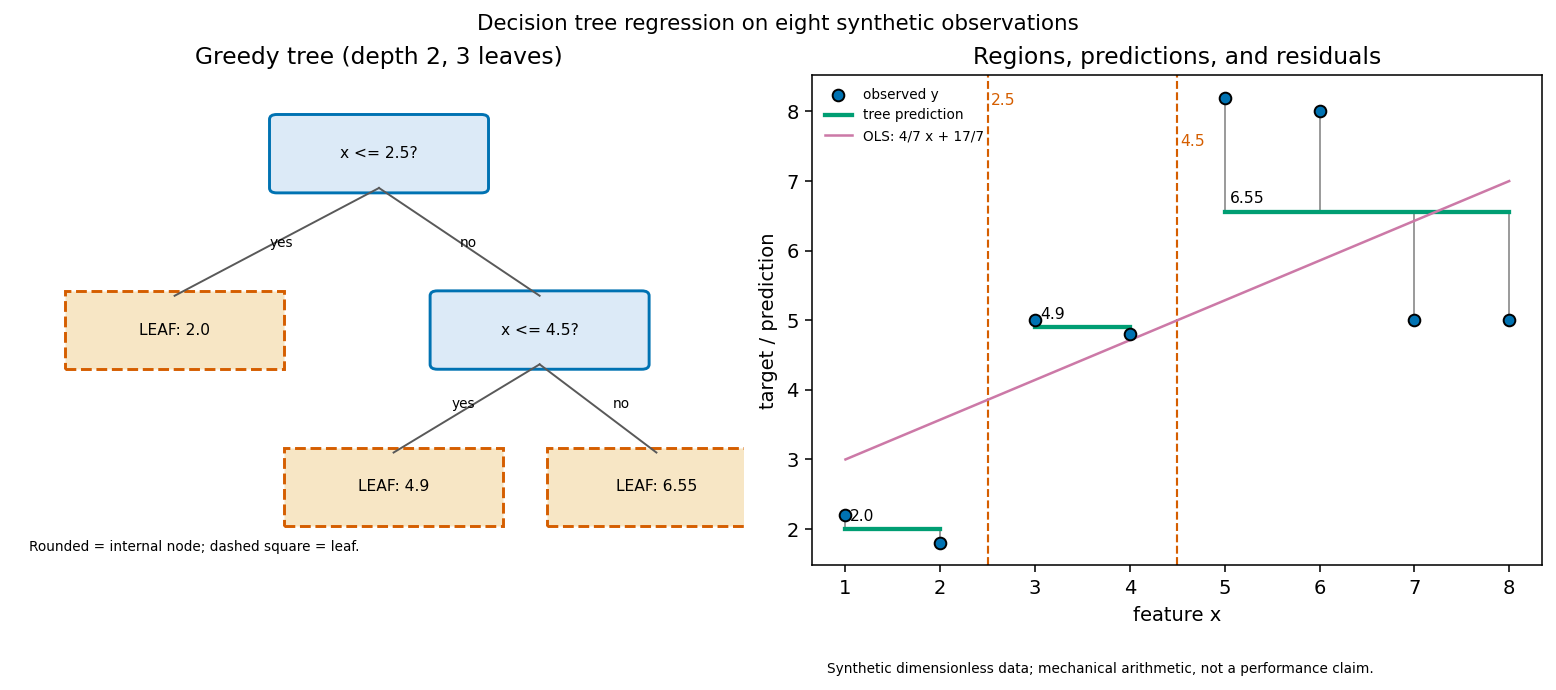

In [8]:
from IPython.display import Image, display
display(Image(filename="assets/decision_tree_panels.png"))

## S10 — Failure modes and bounded interpretation

The same threshold can have different gains in different parent regions: `x <= 6.5` has gain `0` at the root, `3.0` inside `{3..8}`, and `9.61` inside `{5..8}`. A small change to `y_3` from `5.0` to `5.3` flips the right-child choice in the frozen instability probe. These are mechanics on this dataset, not universal claims. Pruning is deferred to 03.07; classification to 03.06; ensembles to 04.x.

## S11 — Exercises

1. Rebuild with `max_depth=3` and report the leaf regions and RSS.
2. Rebuild with `min_samples_leaf=1` and identify the new singleton leaves.
3. Compare mean and median in `{3..8}`.
4. Prove `Delta_RSS >= 0`.
5. Explain why `t=3.0` is not a distinct midpoint candidate.
6. Change `y_3` to `5.3` and report the changed child split.

## S12 — Takeaways, references, and continuity

A regression-tree leaf predicts its region mean under squared loss. Candidate splits are compared by child RSS reduction, and recursive selection is greedy. Depth and leaf count differ, and `<=` determines boundary traversal. The frozen calculations demonstrate the algorithm, not how well it predicts elsewhere.

This lesson completes Module 02. Classification criteria continue in 03.06, pruning in 03.07, and ensembles in 04.x. References include Breiman et al., *Classification and Regression Trees*; the scikit-learn 1.5 Decision Trees User Guide and `DecisionTreeRegressor` API; Hastie, Tibshirani, and Friedman, *The Elements of Statistical Learning*; James et al., *An Introduction to Statistical Learning*; and NumPy 1.26 documentation.

The numbers in this lesson are deterministic calculations on eight synthetic points; they demonstrate how the algorithm works, not how well it will predict on any other data.